In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#  Chargement de l'ensemble des fichier nécessaire à l'analyse

dgccrf = pd.read_csv("table_dgccrf/dataframe_dgccrf_18_11_2026.csv")  #  Table contenant les sanctions de la DGCCRF
siret = pd.read_csv("table_siret/siret_base.csv")  #  Table contenant l'ensemble des SIRET
naf = pd.read_excel("table_naf/code_naf.xls")  #  Table de référence des codes NAF

**NETTOYAGE DES DATAFRAME**

In [33]:
# Nettoyage du DataFrame contenant les sanctions de la DGCCRF

    # 1. Visualisation des colonnes du DF

dgccrf.head(0) 

,Siret,Amende,Raison amende


In [4]:
    # 2. Création d'un rapport de propretée du DF

def data_clean_dgccrf(df : pd.DataFrame) -> dict : 
    quality_report = {
        "Taille du dataframe" : len(df),
        "Nombre de doublons : " : df.duplicated().sum(),
        "Nombre de NaN : " : df.isnull().sum(),
        "Type de valeur de la colonne SIRET : " : df["Siret"].dtype,
        "Type de valeur de la colonne Amende :" : df["Amende"].dtype,
        "Nombre d'amendes hors normes :" : df.loc[df["Amende"] >= 3000000].count(),  #  Valeur jugée hors norme
        "Type de sanction différentes : " : df["Raison amende"].unique()
    }
    return quality_report

quality_dgccrf = data_clean_dgccrf(dgccrf)  #  Variable contenant le rapport pour le DF 

print("\n === RAPPORT DE PROPRETÉE DU DATAFRAME DGCCF ===")
print(quality_dgccrf)


 === RAPPORT DE PROPRETÉE DU DATAFRAME DGCCF ===
{'Taille du dataframe': 131, 'Nombre de doublons : ': np.int64(4), 'Nombre de NaN : ': Siret             0
Amende           10
Raison amende     0
dtype: int64, 'Type de valeur de la colonne SIRET : ': dtype('int64'), 'Type de valeur de la colonne Amende :': dtype('float64'), "Nombre d'amendes hors normes :": Siret            0
Amende           0
Raison amende    0
dtype: int64, 'Type de sanction différentes : ': <StringArray>
['Démarchage téléphonique, Rénovation énergétique',
                              'Délais de paiement',
               'Pratiques commerciales trompeuses',
                  'Autres catégories de sanctions',
                 'Autres thématiques de sanctions',
                              'Affichage des prix',
         'Lutte contre le blanchiment de capitaux',
                            'Défaut d’information',
                                        'Sécurité',
                           'Sécurité des produits',

In [5]:
    # 2. Mise en place de la copy du DF

dgccrf_copy = dgccrf.copy()  #  Copie pour éviter d'écraser les données

    # 3. Traitement des valeurs doublons du DF

dgccrf_copy = dgccrf_copy.drop_duplicates()

    # 4. Traitement des valeurs NaN

dgccrf_copy = dgccrf_copy.dropna(subset=["Amende"])

    # 5. Encodage des valeurs au bon format

dgccrf_copy["Siret"] = dgccrf_copy["Siret"].astype(str)

dgccrf_copy = dgccrf_copy.rename(columns={
    "Siret" : "siret"
})

    # 6. Vérification de la bonne adéquation des sirets

for v in dgccrf_copy["siret"] :  #  Retrait de tous les sirets inférieurs à 14
    if len(v) < 14 :
        dgccrf_copy = dgccrf_copy.loc[dgccrf_copy["siret"] != v]

    # 7. Normalisation des données

dgccrf_copy["siret"] = dgccrf_copy["siret"].str.strip()

    # 8. Rapport post nettoyage

taille_ini = len(dgccrf)
taille_clean = len(dgccrf_copy)
perte =  taille_ini - taille_clean

print("\n === RAPPORT POST NETTOYAGE ===")
print(f"Le nettoyage a fait perdre {perte} données sur un dataframe de {taille_ini} au départ soit {100-((taille_clean * 100)/taille_ini)}% de perte")


 === RAPPORT POST NETTOYAGE ===
Le nettoyage a fait perdre 15 données sur un dataframe de 131 au départ soit 11.45038167938931% de perte


In [34]:
# Nettoyage du DataFrame contenant les sanctions du SIRET

    # 1. Visualisation des colonnes du DF

siret.head(0) 

,siret,code_naf


In [7]:
    # 2. Création d'un rapport de propretée du DF

def data_clean_siret(df : pd.DataFrame) -> dict : 
    count_siret = 0
    for vl in df["siret"].astype(str) : 
        if len(v) < 14 :
            count_siret+=1

    quality_report = {
        "Taille du dataframe" : len(df),
        "Nombre de doublons : " : df.duplicated().sum(),
        "Nombre de NaN : " : df.isnull().sum(),
        "Type de valeur de la colonne SIRET : " : df["siret"].dtype,
        "Type de valeur de la colonne code_naf :" : df["code_naf"].dtype,
        "Nombre de siret mal renseignés" : count_siret
    }
    return quality_report

quality_siret = data_clean_siret(siret)

print("\n === RAPPORT DE PROPRETÉE DU DATAFRAME SIRET ===")
print(quality_siret)


 === RAPPORT DE PROPRETÉE DU DATAFRAME SIRET ===
{'Taille du dataframe': 44503711, 'Nombre de doublons : ': np.int64(0), 'Nombre de NaN : ': siret           0
code_naf    21437
dtype: int64, 'Type de valeur de la colonne SIRET : ': dtype('int64'), 'Type de valeur de la colonne code_naf :': <StringDtype(storage='python', na_value=nan)>, 'Nombre de siret mal renseignés': 0}


In [8]:
    # 3. Création d'un copy du DF

siret_copy = siret.copy()

    # 4. Traitement des valeurs NaN du DF

siret_copy = siret_copy.dropna(subset=["code_naf"])

    # 5. Changement de type de la colonne SIRET

siret_copy["siret"] = siret_copy["siret"].astype(str)

    # 6. Normalisation des colonnes

siret_copy["siret"] = siret_copy["siret"].str.strip()
siret_copy["code_naf"] = siret_copy["code_naf"].str.strip()

    # 6. Rapport post nettoyage

taille_ini = len(siret)
taille_clean = len(siret_copy)
perte =  taille_ini - taille_clean

print("\n === RAPPORT POST NETTOYAGE ===")
print(f"Le nettoyage a fait perdre {perte} données sur un dataframe de {taille_ini} au départ soit {100-((taille_clean * 100)/taille_ini)}% de perte")


 === RAPPORT POST NETTOYAGE ===
Le nettoyage a fait perdre 21437 données sur un dataframe de 44503711 au départ soit 0.04816901673660823% de perte


In [9]:
# Nettoyage du DataFrame contenant les codes NAF

    # 1. Visualisation des colonnes du DF

naf.head(10) 

,ligne,Code,"Intitulés de la NAF rév. 2, version finale","Intitulés NAF rév. 2, \nen 65 caractères","Intitulés NAF rév. 2, \nen 40 caractères"
0,1,NaN,NaN,NaN,NaN
1,2,SECTION A,"AGRICULTURE, SYLVICULTURE ET PÊCHE","AGRICULTURE, SYLVICULTURE ET PÊCHE","AGRICULTURE, SYLVICULTURE ET PÊCHE"
2,3,NaN,NaN,NaN,NaN
3,4,01,"Culture et production animale, chasse et servi...","Culture et production animale, chasse et servi...","Cult. & prod. animale, chasse & sce ann."
4,5,NaN,NaN,NaN,NaN
5,6,01.1,Cultures non permanentes,Cultures non permanentes,Cultures non permanentes
6,7,01.11,"Culture de céréales (à l'exception du riz), de...","Culture de céréales (sf riz) légumineuses, gra...","Cult céréale, légumineuse, graine oléag."
7,8,01.11Z,"Culture de céréales (à l'exception du riz), de...","Culture de céréales (sf riz) légumineuses, gra...","Cult céréale, légumineuse, graine oléag."
8,9,01.12,Culture du riz,Culture du riz,Culture du riz
9,10,01.12Z,Culture du riz,Culture du riz,Culture du riz


In [10]:
    # 2. Création d'un rapport de propretée du DF

def data_clean_naf(df : pd.DataFrame) -> dict : 
    quality_report = {
        "Taille du dataframe" : len(df),
        "Nombre de doublons : " : df.duplicated().sum(),
        "Nombre de NaN : " : df.isnull().sum(),
        "Type de valeur de la colonne Code : " : df["Code"].dtype
    }
    return quality_report

quality_naf = data_clean_naf(naf)

print("\n === RAPPORT DE PROPRETÉE DU DATAFRAME NAF ===")
print(quality_naf)


 === RAPPORT DE PROPRETÉE DU DATAFRAME NAF ===
{'Taille du dataframe': 2109, 'Nombre de doublons : ': np.int64(0), 'Nombre de NaN : ': ligne                                              0
Code                                             381
 Intitulés de la  NAF rév. 2, version finale     381
Intitulés NAF rév. 2, \nen 65 caractères         381
Intitulés NAF rév. 2, \nen 40 caractères         381
dtype: int64, 'Type de valeur de la colonne Code : ': <StringDtype(storage='python', na_value=nan)>}


In [11]:
    # 3. Création d'une copy du DF

naf_copy = naf.copy()

    # 4. Traitement des valeurs NaN

naf_copy = naf_copy.dropna(subset="Code")

    # 5. Normalisation du code en STR

naf_copy["Code"] = naf_copy["Code"].astype(str)

    # 6. Normalisation des colonnes NAF

naf_copy["Code"] = naf_copy["Code"].str.strip()

    # 7. Enrichissement du DF

naf_division = pd.read_csv("table_naf/naf2008_liste_n2.csv")  #  Chargement de la table contenant les division du NAF
naf_division = naf_division.dropna(subset="Code")  #  Retrait des potentielles NaN
naf_division["Code"] = naf_division["Code"].astype(str)  #  Passage du code en NAF pour jointure
naf_division["Code"] = naf_division["Code"].str.zfill(2)  #  Uniformisation du code NAF
naf_division["Libellé"] = naf_division["Libellé"].str.strip()  #  Retrait des espaces invisibles

naf_copy["Division"] = naf_copy["Code"].str[:2].map(naf_division.set_index("Code")["Libellé"])

naf_copy = naf_copy.dropna(subset="Division")

naf_copy = naf_copy.rename(columns={
    "Code" : "code_naf"
})

    # 8. Drop des colonnes inutiles

usefull_cols = [
    "code_naf", 
    "Division"
]

for c in naf_copy.columns : 
    if c not in usefull_cols : 
        naf_copy = naf_copy.drop(c, axis=1)

    # 9. Rapport post nettoyage

taille_ini = len(naf)
taille_clean = len(naf_copy)
perte =  taille_ini - taille_clean

print("\n === RAPPORT POST NETTOYAGE ===")
print(f"Le nettoyage a fait perdre {perte} données sur un dataframe de {taille_ini} au départ soit {100-((taille_clean * 100)/taille_ini)}% de perte")


 === RAPPORT POST NETTOYAGE ===
Le nettoyage a fait perdre 402 données sur un dataframe de 2109 au départ soit 19.061166429587487% de perte


**FUSION DES DATAFRAMES**

In [12]:
# Fusion de l'ensemble des données en un jeu unique

    # 1. Fusion des Dataframe SIRET et Code NAF

siret_naf = pd.merge(siret_copy, naf_copy, on="code_naf")  #  Fusion sur le code NAF

    # 2. Fusion des Dataframe SIRET_NAF et DGCCRF

dgccrf_siret_naf = pd.merge(dgccrf_copy, siret_naf, on="siret")  #  Fusion sur le SIRET

**ANALYSE EXPLORATOIRE**

In [13]:
# Analyse exploratoire des données

    # 1. Analyse globale du DF

def descriptive_analyse(df : pd.DataFrame) -> dict : 
    descriptive_stats = {
        "Taille du jeu de donnée : " : len(df),
        "Nombre total d'amendes sur la période" : df["Amende"].count(),
        "Tarif moyen d'une amende : " : df["Amende"].mean().round(2),
        "Tarif médian d'une amende" : df["Amende"].median().round(2),
        "Ecart type entre les amendes" : df["Amende"].std().round(2),
        "Tarif minimal d'une amende : " : df["Amende"].min().round(2),
        "Tarif maximal d'une amende : " : df["Amende"].max().round(2),
        "Montant total généré par les amendes :" : sum(df["Amende"]),
        "Nombre de secteur sanctionnés vs. total secteur :" : f"{abs(df["Division"].unique().value_counts().sum() - naf_division["Libellé"].unique().value_counts().sum())} / {naf_division["Libellé"].unique().value_counts().sum()}"
    }
    return descriptive_stats

rapport_sanction = descriptive_analyse(dgccrf_siret_naf)

print("\n === ANALYSE DESCRIPTIVE DU DATAFRAME ===")
print(rapport_sanction)


 === ANALYSE DESCRIPTIVE DU DATAFRAME ===
{'Taille du jeu de donnée : ': 115, "Nombre total d'amendes sur la période": np.int64(115), "Tarif moyen d'une amende : ": np.float64(273233.93), "Tarif médian d'une amende": np.float64(75000.0), 'Ecart type entre les amendes': np.float64(477956.45), "Tarif minimal d'une amende : ": np.float64(2000.0), "Tarif maximal d'une amende : ": np.float64(2450000.0), 'Montant total généré par les amendes :': 31421902.0, 'Nombre de secteur sanctionnés vs. total secteur :': '46 / 88'}


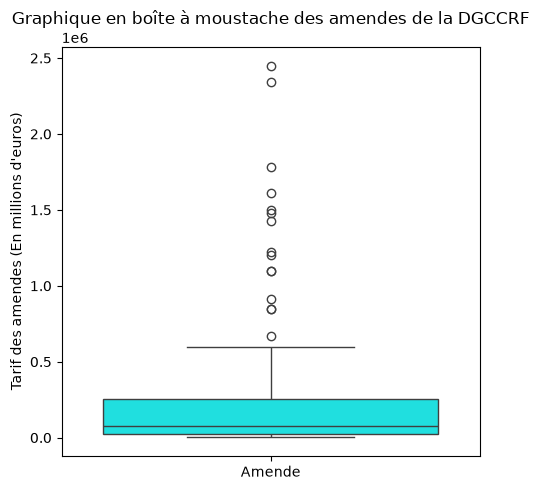

In [14]:
    # 2. Analyse de la répartition des valeurs outliers

plt.figure(figsize=(5,5))
sns.boxplot(data=dgccrf_siret_naf, color="cyan")
plt.title("Graphique en boîte à moustache des amendes de la DGCCRF")
plt.ylabel("Tarif des amendes (En millions d'euros)")
plt.tight_layout()

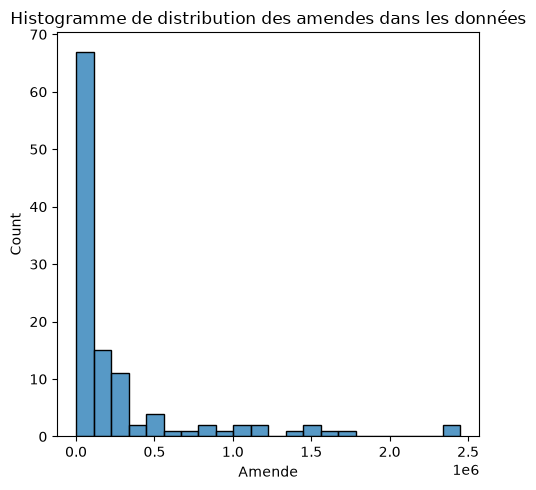

In [15]:
    # 3. Analyse de la distribution des amendes

plt.figure(figsize=(5,5))
sns.histplot(dgccrf_siret_naf["Amende"])
plt.title("Histogramme de distribution des amendes dans les données")
plt.tight_layout()

**SEGMENTATION ET ANALYSE EN REPONSE A LA QUESTION**

In [16]:
# Segmentation et réponse à la question business

    # 1. Répartition des amendes par secteur d'activités

secteur_amendes_count = dgccrf_siret_naf.groupby("Division").Amende.count().sort_values(ascending=False).reset_index().rename(columns={"Amende" : "Nombre amende"})  #  Calcul du nombre d'amende par secteurs

    # 2. Répartition des sommes d'amendes par secteur d'activités

secteur_amendes_sum = dgccrf_siret_naf.groupby("Division").Amende.sum().sort_values(ascending=False).reset_index().rename(columns={"Amende" : "Somme amende"})   #  Calcul du nombre d'amende par secteurs

    # 3. Création d'un tableau d'analyse

secteur_amende = pd.merge(secteur_amendes_sum, secteur_amendes_count, on="Division")  #  Tableau contenant l'ensemble des données

    # 4. Création d'un tableau contenant l'ensemble des Division avec les chiffres associés

secteurs_amende_global = naf_division.copy().drop("Code", axis=1)  #  Copie du DF contenant l'ensemble des donnnées

secteurs_amende_global["Nombre amende"] = secteurs_amende_global["Libellé"].map(secteur_amendes_count.set_index("Division")["Nombre amende"]).fillna(0)  #  Rajout du nombre d'amende

secteurs_amende_global["Somme amende"] = secteurs_amende_global["Libellé"].map(secteur_amendes_sum.set_index("Division")["Somme amende"]).fillna(0)  #  Rajout des somme d'amende

    # 5. Enrichissement de la donnée

total_nb_amende = sum(secteurs_amende_global["Nombre amende"])  #  Nombre total d'amende distribuée
total_sum_amende = sum(secteurs_amende_global["Somme amende"])  #  Montant total généré par les amendes

secteurs_amende_global["pct_nb_secteur"] = ((secteurs_amende_global["Nombre amende"] / total_nb_amende) * 100).round(2)  #  Calcul du pourcentage représentatif

secteurs_amende_global["pct_tar_secteur"] = ((secteurs_amende_global["Somme amende"] / total_sum_amende) * 100).round(2)  #  Calcul du pourcentage représentatif

secteurs_amende_global.sort_values(by="Nombre amende", ascending=False).head(10)  #  Visualisation des 10 secteurs ayant le plus d'amende

,Libellé,Nombre amende,Somme amende,pct_nb_secteur,pct_tar_secteur
41,"Commerce de gros, à l'exception des automobile...",19.0,4621000.0,16.52,14.71
61,Activités des sièges sociaux ; conseil de gestion,7.0,4299000.0,6.09,13.68
18,Industrie chimique,6.0,646900.0,5.22,2.06
43,Transports terrestres et transport par conduites,6.0,101000.0,5.22,0.32
26,Fabrication de machines et équipements n.c.a.,6.0,1159000.0,5.22,3.69
8,Industries alimentaires,5.0,950000.0,4.35,3.02
28,Fabrication d'autres matériels de transport,5.0,1523000.0,4.35,4.85
24,"Fabrication de produits informatiques, électro...",4.0,2844000.0,3.48,9.05
42,"Commerce de détail, à l'exception des automobi...",4.0,264000.0,3.48,0.84
37,Construction de bâtiments,3.0,775000.0,2.61,2.47


In [17]:
secteurs_amende_global.sort_values(by="Somme amende", ascending=False).head(10)  #  Visualisation des 10 secteurs ayant les quantités d'amendes les plus élevées

,Libellé,Nombre amende,Somme amende,pct_nb_secteur,pct_tar_secteur
41,"Commerce de gros, à l'exception des automobile...",19.0,4621000.0,16.52,14.71
61,Activités des sièges sociaux ; conseil de gestion,7.0,4299000.0,6.09,13.68
24,"Fabrication de produits informatiques, électro...",4.0,2844000.0,3.48,9.05
46,Entreposage et services auxiliaires des transp...,3.0,2575000.0,2.61,8.19
67,Activités de location et location-bail,2.0,1832000.0,1.74,5.83
53,Télécommunications,2.0,1733000.0,1.74,5.52
28,Fabrication d'autres matériels de transport,5.0,1523000.0,4.35,4.85
26,Fabrication de machines et équipements n.c.a.,6.0,1159000.0,5.22,3.69
74,Enseignement,1.0,1100002.0,0.87,3.50
19,Industrie pharmaceutique,2.0,1006000.0,1.74,3.20


In [18]:
# Analyse de la répartition du type d'amende : 

    # 1. Calcul du nombre d'amende peu importe le secteur
amende_count = dgccrf_siret_naf.groupby("Raison amende").siret.count().sort_values(ascending=False)

    # 2. Calcul du type d'amende par secteur

secteur_count = dgccrf_siret_naf.groupby(["Raison amende", "Division"]).siret.count().sort_values(ascending=False)

    # 3. Affichage du résultat du .1

amende_count

Raison amende
Délais de paiement                                 97
Démarchage téléphonique, Rénovation énergétique     5
Pratiques commerciales trompeuses                   4
Défaut d’information                                2
Affichage des prix                                  1
Autres catégories de sanctions                      1
Influenceurs                                        1
Lutte contre le blanchiment de capitaux             1
Pratiques restrictives de concurrence               1
Sécurité                                            1
Sécurité des produits                               1
Name: siret, dtype: int64

In [19]:
    # 3. Affichage du résultat du .2

secteur_count

Raison amende                                    Division                                                                                                                   
Délais de paiement                               Commerce de gros, à l'exception des automobiles et des motocycles                                                              16
                                                 Activités des sièges sociaux ; conseil de gestion                                                                               6
                                                 Industrie chimique                                                                                                              6
                                                 Transports terrestres et transport par conduites                                                                                6
                                                 Fabrication de machines et équipements n.c.a.                 

**EXPORT DES DONNÉES POUR LE RAPPORT**

In [31]:
# Exporation des données pour le rapport BI

    # 1. Récupération des données globales

dgccrf_siret_naf_copy = dgccrf_siret_naf.copy()  #  Sauvegarde
dgccrf_siret_naf_copy = dgccrf_siret_naf_copy.drop(["siret"], axis=1)  #  Anonymisation de la table  

dgccrf_siret_naf_copy.to_csv("rapport_bi/dgccrf_siret_naf.csv", index=False)

    # 2. Récupération des données de segmententation

secteurs_amende_global.to_csv("rapport_bi/segmentation_dgccrf.csv", index=False)
